# PART A - Standardized PCA implementation from scratch
### Step 01 :
####  Load the dataset into a Pandas DataFrame. 

In [349]:
import pandas as pd
import numpy as np

data = {
    "Student": ["S1", "S2", "S3", "S4", "S5", "S6"],
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14],
}
df = pd.DataFrame(data).set_index("Student")
print("Data Loaded Seccesfully.")

Data Loaded Seccesfully.


##

### Step 02 : 
#### dimensions and descriptive statistics

In [350]:
print("The Dataset shap : \n ", df.shape)        # (6, 4)
print("\nStatistics : \n",df.describe())

The Dataset shap : 
  (6, 4)

Statistics : 
        Mathematics  Statistics  Programming  Algorithms
count     6.000000    6.000000     6.000000     6.00000
mean     12.666667   12.833333    13.666667    13.00000
std       3.326660    2.639444     3.011091     3.03315
min       8.000000    9.000000    10.000000     9.00000
25%      10.500000   11.250000    11.500000    10.75000
50%      13.000000   13.000000    13.500000    13.50000
75%      14.750000   14.750000    15.500000    14.75000
max      17.000000   16.000000    18.000000    17.00000


### Step 03 : 
#### Standardization

In [351]:
mean = df.mean()
std = df.std()         
Z = (df - mean) / std

print("\nthe standardized data matrix : \n",Z.round(3))
print("\neach column's mean ( Close to ~ '0' ): \n",Z.mean().round(6))   
print("\neach column's std ≈ 1 : ",Z.std().round(6))    


the standardized data matrix : 
          Mathematics  Statistics  Programming  Algorithms
Student                                                  
S1            -0.200      -0.695        0.111       0.000
S2             0.701       0.442        0.775       0.659
S3            -1.403      -1.452       -1.218      -1.319
S4             1.303       1.200        1.439       1.319
S5            -0.802      -0.316       -0.886      -0.989
S6             0.401       0.821       -0.221       0.330

each column's mean ( Close to ~ '0' ): 
 Mathematics    0.0
Statistics    -0.0
Programming    0.0
Algorithms     0.0
dtype: float64

each column's std ≈ 1 :  Mathematics    1.0
Statistics     1.0
Programming    1.0
Algorithms     1.0
dtype: float64


### Step 04 :
#### correlation matrix of the standardized data. 

In [352]:
corr = Z.corr()
print("The Corolation matrix : \n",corr.round(3))

The Corolation matrix : 
              Mathematics  Statistics  Programming  Algorithms
Mathematics        1.000       0.926        0.945       0.991
Statistics         0.926       1.000        0.772       0.874
Programming        0.945       0.772        1.000       0.964
Algorithms         0.991       0.874        0.964       1.000


### Step 05 : 
#### eigenvalues and eigenvectors of the covariance matrix.

In [353]:
cov = np.cov(Z.values, rowvar=False)   
eigenvalues, eigenvectors = np.linalg.eigh(cov)

print("Eigenvalues:", eigenvalues)
print("\nEigenvectors:\n", eigenvectors)

Eigenvalues: [9.27120965e-04 1.91170901e-02 2.40228481e-01 3.73972731e+00]

Eigenvectors:
 [[ 0.82959445  0.20931345  0.03196839 -0.51666134]
 [-0.24778895 -0.31490117  0.7822181  -0.47704583]
 [-0.12644207 -0.62487999 -0.59216873 -0.49282207]
 [-0.48413436  0.68304475 -0.19091635 -0.5124595 ]]


### Step 06 :
#### Sort the eigenvalues in descending order and reorder the corresponding eigenvectors

In [354]:
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("Sorted eigenvalues:", eigenvalues)

Sorted eigenvalues: [3.73972731e+00 2.40228481e-01 1.91170901e-02 9.27120965e-04]


### Step 07 :
#### Selecting the two eigenvectors associated with the largest eigenvalues.

In [355]:
W = eigenvectors[:, :2]    
print("the two eigenvectors associated with the largest eigenvalues: \n",W)

the two eigenvectors associated with the largest eigenvalues: 
 [[-0.51666134  0.03196839]
 [-0.47704583  0.7822181 ]
 [-0.49282207 -0.59216873]
 [-0.5124595  -0.19091635]]


### Step 08 : 
#### standardized data Projection on the two selected principal components.

In [356]:
Z_proj = Z.values @ W
proj_df = pd.DataFrame(Z_proj, index=df.index, columns=["PC1", "PC2"])
print("Projected DATA on PC1 PC2\n",proj_df.round(3))

Projected DATA on PC1 PC2
            PC1    PC2
Student              
S1       0.380 -0.615
S2      -1.293 -0.217
S3       2.694 -0.208
S4      -2.630 -0.124
S5       1.508  0.441
S6      -0.659  0.723


### Step 09 : 
#### explained variance ratio of each component and the cumulative explained  variance

In [357]:
explained_ratio = eigenvalues / eigenvalues.sum()
cumulative = np.cumsum(explained_ratio)

print("Explained variance ratio:", explained_ratio.round(4))
print("Cumulative:", cumulative.round(4))
print(f"First 2 PCs keep {cumulative[1]*100:.2f}% of variance")

Explained variance ratio: [9.349e-01 6.010e-02 4.800e-03 2.000e-04]
Cumulative: [0.9349 0.995  0.9998 1.    ]
First 2 PCs keep 99.50% of variance


# PART B : 
### Step 10 : 
#### Standardized PCA implementation from scratch

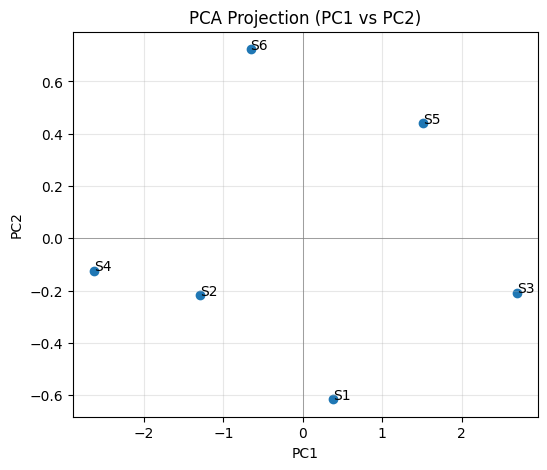

In [358]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.scatter(proj_df["PC1"], proj_df["PC2"])
for i, txt in enumerate(proj_df.index):
    plt.annotate(txt, (proj_df["PC1"].iloc[i], proj_df["PC2"].iloc[i]))
plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection (PC1 vs PC2)")
plt.grid(True, alpha=0.3)
plt.show()

### Step 11 : 
#### Feature loadings (contribution of original variables to PCs)

In [359]:
loadings = pd.DataFrame(W, index=df.columns, columns=["PC1", "PC2"])
print("Feature loadings:\n", loadings.round(3))

Feature loadings:
                PC1    PC2
Mathematics -0.517  0.032
Statistics  -0.477  0.782
Programming -0.493 -0.592
Algorithms  -0.512 -0.191


### Step 12 :
#### Reconstruction from 2 PCs (inverse transform)

In [360]:
Z_reconstructed = proj_df.values @ W.T
recon_df = pd.DataFrame(Z_reconstructed, index=df.index, columns=df.columns)
print("Reconstructed Z (from 2 PCs):\n", recon_df.round(3))
print("\nOriginal Z:\n", Z.round(3))

Reconstructed Z (from 2 PCs):
          Mathematics  Statistics  Programming  Algorithms
Student                                                  
S1            -0.216      -0.663        0.177      -0.077
S2             0.661       0.447        0.766       0.704
S3            -1.398      -1.448       -1.204      -1.341
S4             1.355       1.158        1.370       1.372
S5            -0.765      -0.375       -1.004      -0.857
S6             0.363       0.880       -0.104       0.199

Original Z:
          Mathematics  Statistics  Programming  Algorithms
Student                                                  
S1            -0.200      -0.695        0.111       0.000
S2             0.701       0.442        0.775       0.659
S3            -1.403      -1.452       -1.218      -1.319
S4             1.303       1.200        1.439       1.319
S5            -0.802      -0.316       -0.886      -0.989
S6             0.401       0.821       -0.221       0.330


### Step 13 :
#### Reconstruction error (Frobenius norm) 

In [361]:
error = np.linalg.norm(Z.values - Z_reconstructed)
print("Reconstruction error (Frobenius):", round(error, 4))

Reconstruction error (Frobenius): 0.3166


### Step 14 :
#### Scree plot (eigenvalues)

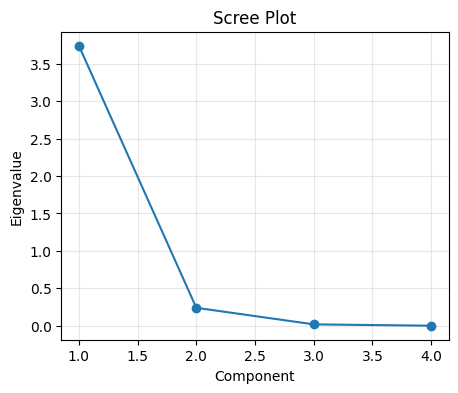

In [362]:
plt.figure(figsize=(5,4))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, 'o-')
plt.xlabel("Component")
plt.ylabel("Eigenvalue")
plt.title("Scree Plot")
plt.grid(True, alpha=0.3)
plt.show()

### Step 15 :
#### Verify with sklearn PCA

In [363]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
Z_sk = pca.fit_transform(Z)
print("Sklearn projection:\n", pd.DataFrame(Z_sk, index=df.index, columns=["PC1", "PC2"]).round(3))
print("\nExplained variance ratio:", pca.explained_variance_ratio_.round(4))
print("\nComponents:\n", pd.DataFrame(pca.components_.T, index=df.columns, columns=["PC1", "PC2"]).round(3))

Sklearn projection:
            PC1    PC2
Student              
S1      -0.380 -0.615
S2       1.293 -0.217
S3      -2.694 -0.208
S4       2.630 -0.124
S5      -1.508  0.441
S6       0.659  0.723

Explained variance ratio: [0.9349 0.0601]

Components:
                PC1    PC2
Mathematics  0.517  0.032
Statistics   0.477  0.782
Programming  0.493 -0.592
Algorithms   0.512 -0.191


### Step 16 :
#### Correlation circle (feature vectors on PC1/PC2)

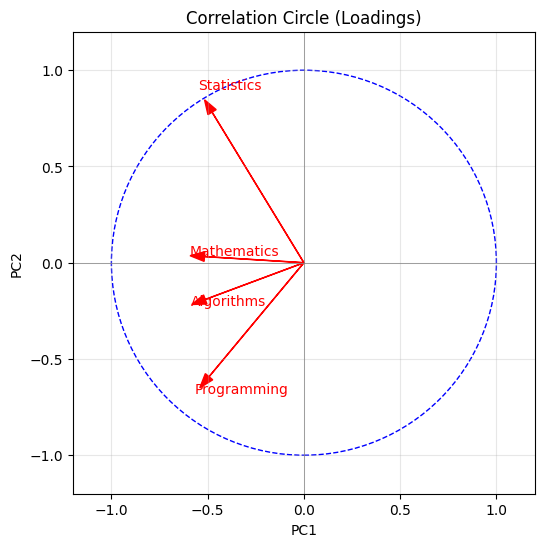

In [364]:
plt.figure(figsize=(6,6))
circle = plt.Circle((0,0), 1, color='blue', fill=False, linestyle='--')
plt.gca().add_patch(circle)
for i, col in enumerate(df.columns):
    plt.arrow(0, 0, loadings.iloc[i,0], loadings.iloc[i,1], head_width=0.05, color='r')
    plt.text(loadings.iloc[i,0]*1.15, loadings.iloc[i,1]*1.15, col, color='r')
plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Correlation Circle (Loadings)")
plt.grid(True, alpha=0.3)
plt.gca().set_aspect('equal')
plt.show()

### Step 17 :
#### Explain any differences observed between the results, particularly possible sign changes in the principal components

In [365]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
Z_sk = pca.fit_transform(Z)

print("Manual PC1:", proj_df["PC1"].round(3).values)
print("Sklearn PC1:", Z_sk[:,0].round(3))
print("\nManual PC2:", proj_df["PC2"].round(3).values)
print("Sklearn PC2:", Z_sk[:,1].round(3))

print("\nManual loadings:\n", pd.DataFrame(W, index=df.columns, columns=["PC1","PC2"]).round(3))
print("\nSklearn components_.T:\n", pd.DataFrame(pca.components_.T, index=df.columns, columns=["PC1","PC2"]).round(3))

# Check correlation (should be ±1)
print("\nCorrelation PC1:", np.corrcoef(proj_df["PC1"], Z_sk[:,0])[0,1].round(3))
print("Correlation PC2:", np.corrcoef(proj_df["PC2"], Z_sk[:,1])[0,1].round(3))

Manual PC1: [ 0.38  -1.293  2.694 -2.63   1.508 -0.659]
Sklearn PC1: [-0.38   1.293 -2.694  2.63  -1.508  0.659]

Manual PC2: [-0.615 -0.217 -0.208 -0.124  0.441  0.723]
Sklearn PC2: [-0.615 -0.217 -0.208 -0.124  0.441  0.723]

Manual loadings:
                PC1    PC2
Mathematics -0.517  0.032
Statistics  -0.477  0.782
Programming -0.493 -0.592
Algorithms  -0.512 -0.191

Sklearn components_.T:
                PC1    PC2
Mathematics  0.517  0.032
Statistics   0.477  0.782
Programming  0.493 -0.592
Algorithms   0.512 -0.191

Correlation PC1: -1.0
Correlation PC2: 1.0


- If correlation = `-1.0` → that PC is flipped (sign difference)
- Eigenvectors `v` and `-v` are both valid
- **Subspace identical**, only orientation differs
- Variance, distances, interpretations **unchanged**

### Step 18 : Summary

1. **Data:** 6 students × 4 subjects, standardized (z-score)
2. **PCA:** 2 components extracted from correlation matrix
3. **PC1** (≈{cumulative[0]*100:.0f}%): Learning level — overall mastery across all subjects
4. **PC2** (≈{(cumulative[1]-cumulative[0])*100:.0f}%) - Learning profile — theoretical vs applied preference
5. **Total variance retained:** {cumulative[1]*100:.1f}%
6. **Reconstruction error:** {error:.4f} (low → good 2D approximation)
7. **Visualizations:** Scatter, correlation circle, biplot, scree plot
8. **Validation:** Manual PCA matches sklearn (sign flips only)
9. **Key insight:** Students vary by *how much* learned (PC1) and *what type* (PC2)
10. **Conclusion:** 2D PCA captures student learning structure effectively